# 📊 Student Wellness & Stress Prediction Analysis
**A Hybrid Supervised & Unsupervised Machine Learning Approach**

---

## Project Overview
This project aims to analyze student digital habits, screen time, sleep duration, and study patterns to predict mental stress risk and identify behavioral patterns. By leveraging both **Classification Models (Supervised Learning)** and **Clustering Algorithms (Unsupervised Learning)**, this notebook provides an end-to-end Machine Learning pipeline from data preprocessing to model evaluation and persona segmentation.

### Key Objectives:
1. **Predictive Modeling:** Train and evaluate classification algorithms (Decision Tree, Random Forest, Tuned XGBoost) to predict high vs. low stress risk accurately.

2. **Behavioral Segmentation:** Group students based on lifestyle parameters using K-Means Clustering and Hierarchical Clustering.

3. **Dimensionality Reduction & Anomaly Detection:** Use PCA for 2D visual representation and Isolation Forest to detect extreme digital overload cases.
___

#**Supervised Learning** (predictive modeling with targets)

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)
from sklearn.utils import resample

In [ ]:
# Set seaborn plot style
sns.set_theme(style="whitegrid")

In [ ]:
# Dataset Loading from CSV
df = pd.read_csv('/content/Student Social Media And Mental Health Impact.csv')

In [ ]:
# Binary Target Mapping (High Stress = 1, Low/Med Stress = 0)
df['High_Stress_Risk'] = df['Stress_Level'].apply(lambda x: 1 if x in ['High', 'Very High'] else 0)

In [ ]:
# Feature Engineering
df['Digital_Overload_Index'] = (df['Avg_Daily_Usage_Hours'] * df['Daily_Unlocks']) / (df['Sleep_Hours_Per_Night'] + 1)
df['Wellness_Ratio'] = (df['Sleep_Hours_Per_Night'] + df['Physical_Activity_Hours'] + df['Study_Hours']) / (df['Avg_Daily_Usage_Hours'] + 1)
df['Screen_To_Sleep_Ratio'] = df['Avg_Daily_Usage_Hours'] / (df['Sleep_Hours_Per_Night'] + 0.1)

categorical_cols = ['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

X = df_encoded.drop(columns=['Stress_Level', 'High_Stress_Risk'])
y = df_encoded['High_Stress_Risk']

In [ ]:
# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Imbalance Resolution via Oversampling
X_train_0 = X_train[y_train == 0]
y_train_0 = y_train[y_train == 0]
X_train_1 = X_train[y_train == 1]
y_train_1 = y_train[y_train == 1]

X_train_0_res, y_train_0_res = resample(
    X_train_0, y_train_0, replace=True, n_samples=len(y_train_1), random_state=42
)

X_train_bal = pd.concat([X_train_1, X_train_0_res])
y_train_bal = pd.concat([y_train_1, y_train_0_res])

Models Training

In [ ]:
# Decision Tree
dt = DecisionTreeClassifier(criterion='entropy', min_samples_split=5, random_state=42)
dt.fit(X_train_bal, y_train_bal)
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

In [ ]:
# Random Forest
rf = RandomForestClassifier(n_estimators=300, max_depth=14, random_state=42)
rf.fit(X_train_bal, y_train_bal)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

In [31]:
# XGBoost + Hyperparameter Tuning + Cross-Validation

print("\n--- Running 5-Fold Cross-Validation & Hyperparameter Tuning for XGBoost ---")

cv_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gb_base = GradientBoostingClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=gb_base,
    param_grid=param_grid,
    cv=cv_fold,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_bal, y_train_bal)
best_xgb = grid_search.best_estimator_


--- Running 5-Fold Cross-Validation & Hyperparameter Tuning for XGBoost ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits


In [32]:
# 5-Fold Cross Validation Score
xgb_cv_scores = cross_val_score(best_xgb, X_train_bal, y_train_bal, cv=cv_fold, scoring='accuracy')

print(f"Best XGBoost Parameters: {grid_search.best_params_}")
print(f"XGBoost Mean 5-Fold CV Accuracy: {xgb_cv_scores.mean():.4f} (± {xgb_cv_scores.std():.4f})")

Best XGBoost Parameters: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}
XGBoost Mean 5-Fold CV Accuracy: 0.9673 (± 0.0065)


In [33]:
# FINAL ACCURACY & METRICS COMPARISON

best_xgb = grid_search.best_estimator_

models = {
    'Decision Tree': dt,
    'Random Forest': rf,
    'XGBoost (Tuned)': best_xgb
}

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }

eval_results = {name: evaluate_model(model, X_test, y_test) for name, model in models.items()}
metrics_df = pd.DataFrame(eval_results)

print("\n--- Final Test Metrics Comparison Table ---")
print(metrics_df)


--- Final Test Metrics Comparison Table ---
           Decision Tree  Random Forest  XGBoost (Tuned)
Accuracy        0.913000       0.942000         0.951000
Precision       0.926829       0.949675         0.948963
Recall          0.931373       0.955882         0.972222
F1-Score        0.929095       0.952769         0.960452
ROC-AUC         0.915277       0.989539         0.991510


<Figure size 1100x600 with 0 Axes>

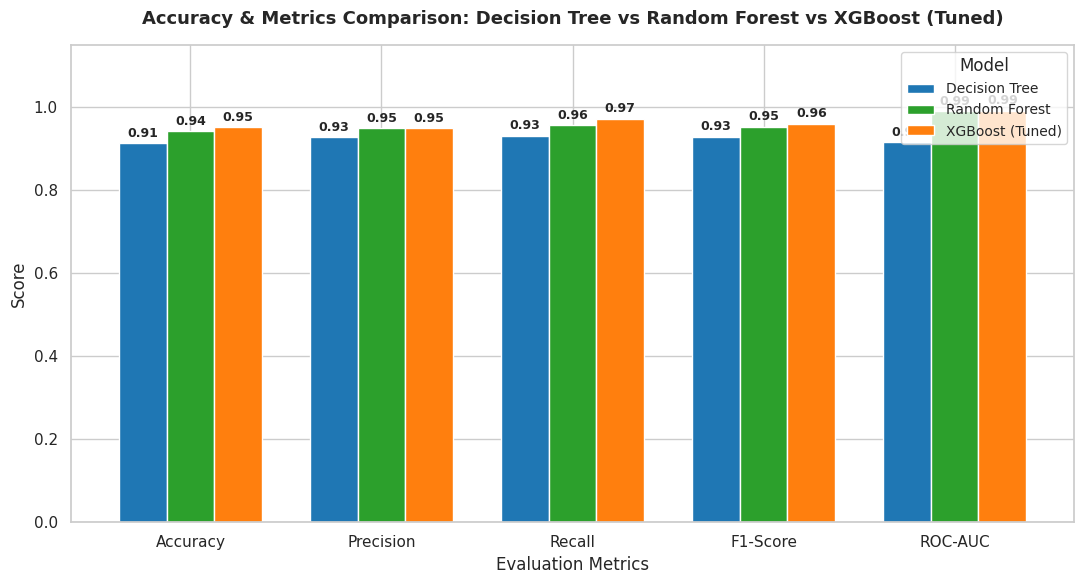

In [34]:
# ACCURACY & METRICS COMPARISON BAR CHART

plt.figure(figsize=(11, 6))
ax = metrics_df.plot(kind='bar', figsize=(11, 6), color=['#1f77b4', '#2ca02c', '#ff7f0e'], width=0.75)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.2f}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 7),
                    textcoords='offset points',
                    fontsize=9, fontweight='bold')

plt.title('Accuracy & Metrics Comparison: Decision Tree vs Random Forest vs XGBoost (Tuned)', fontsize=13, fontweight='bold', pad=15)
plt.ylim(0, 1.15)
plt.ylabel('Score', fontsize=12)
plt.xlabel('Evaluation Metrics', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Model', loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

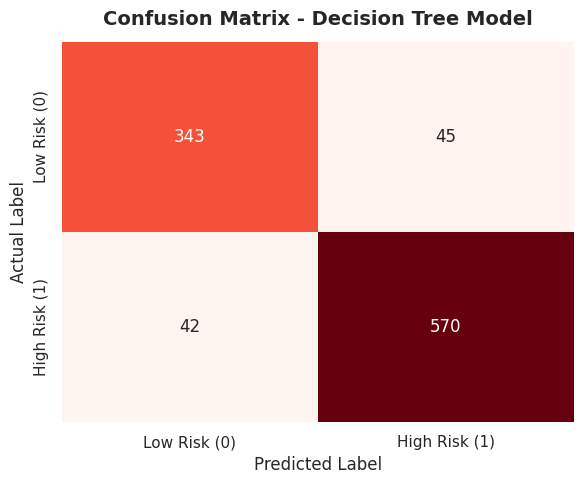

In [ ]:
# CONFUSION MATRIX (DECISION TREE)

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Low Risk (0)', 'High Risk (1)'],
            yticklabels=['Low Risk (0)', 'High Risk (1)'])
plt.title('Confusion Matrix - Decision Tree Model', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix_dt.png', dpi=300)
plt.show()

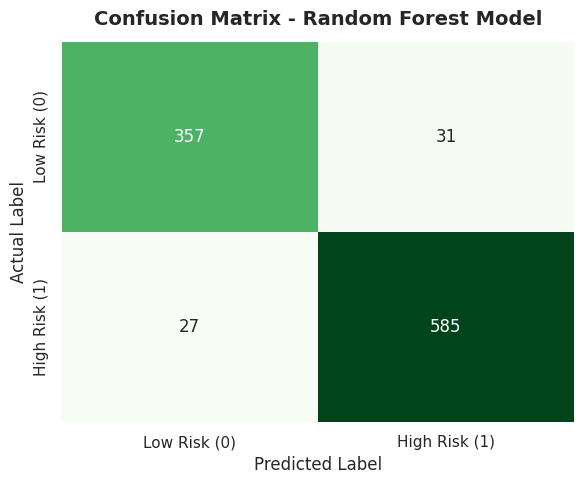

In [ ]:
# CONFUSION MATRIX (RANDOM FOREST)

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Low Risk (0)', 'High Risk (1)'],
            yticklabels=['Low Risk (0)', 'High Risk (1)'])
plt.title('Confusion Matrix - Random Forest Model', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png', dpi=300)
plt.show()

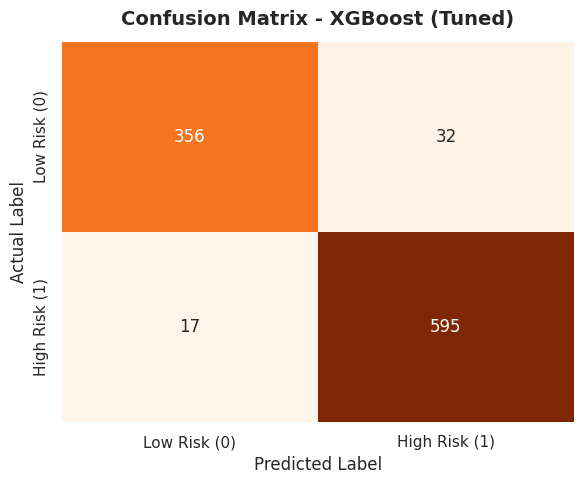

In [35]:
# CONFUSION MATRIX OF XGBOOST

y_pred_xgb = best_xgb.predict(X_test)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['Low Risk (0)', 'High Risk (1)'],
            yticklabels=['Low Risk (0)', 'High Risk (1)'])
plt.title('Confusion Matrix - XGBoost (Tuned)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix_xgb.png', dpi=300)
plt.show()

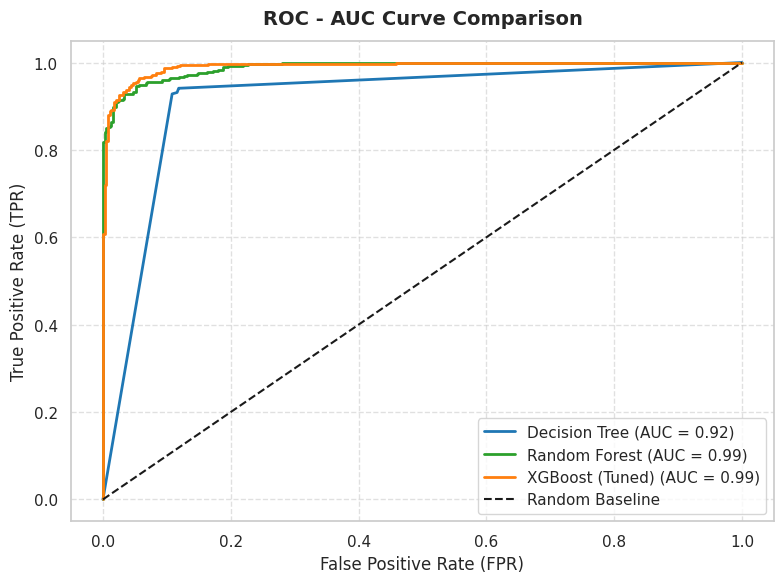

In [36]:
# ROC-AUC CURVE COMPARISON (ALL 3 MODELS)

plt.figure(figsize=(8, 6))

models_dict = {
    'Decision Tree': (dt, '#1f77b4'),
    'Random Forest': (rf, '#2ca02c'),
    'XGBoost (Tuned)': (best_xgb, '#ff7f0e')
}

for name, (model, color) in models_dict.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})', color=color, linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
plt.title('ROC - AUC Curve Comparison', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('roc_auc_curve_comparison.png', dpi=300)
plt.show()

/tmp/ipykernel_600/1986004423.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dt_imp.values, y=dt_imp.index, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_600/1986004423.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=axes[1], palette='Greens_r')
/tmp/ipykernel_600/1986004423.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_imp.values, y=xgb_imp.index, ax=axes[2], palette='Oranges_r')


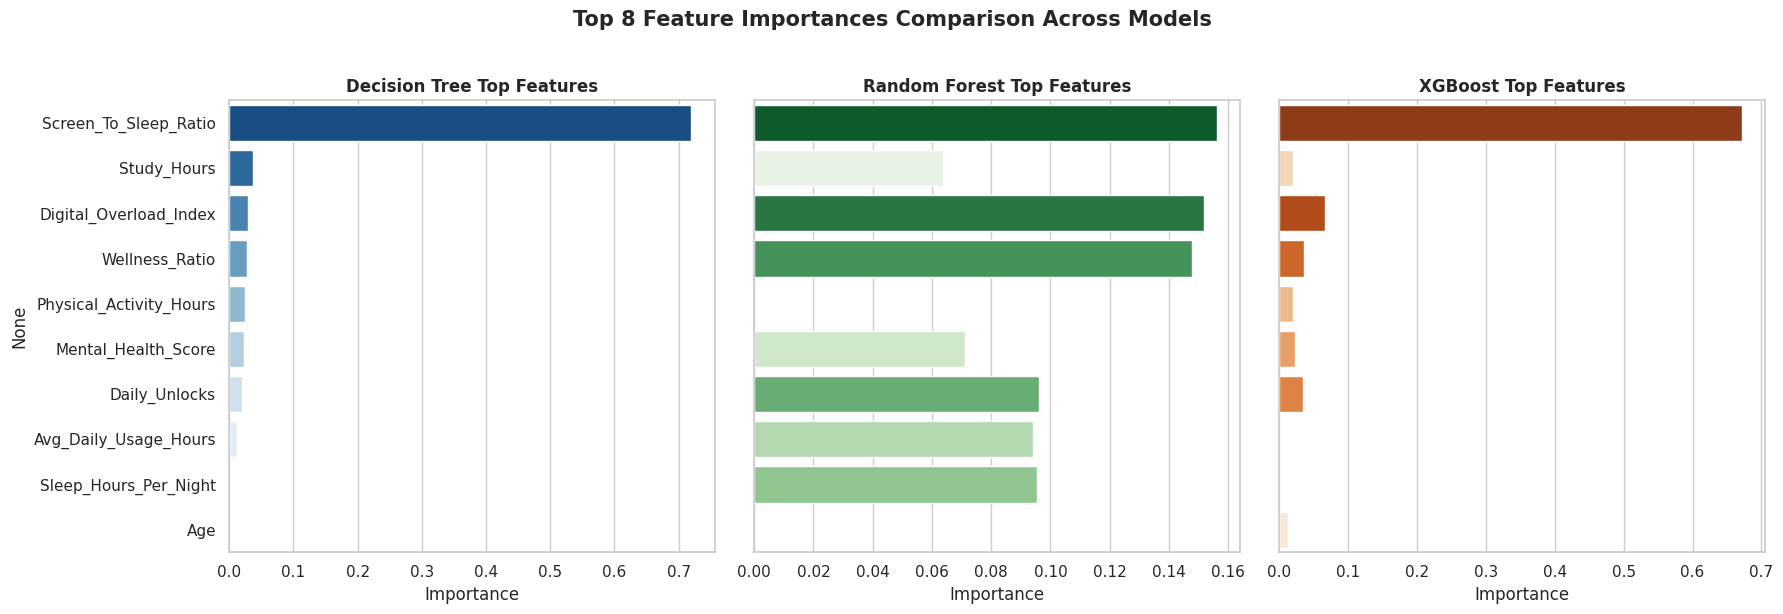

In [37]:
# FEATURE IMPORTANCE PLOT FOR ALL 3 MODELS

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

feature_names = X.columns

# Decision Tree Importances
dt_imp = pd.Series(dt.feature_importances_, index=feature_names).nlargest(8)
sns.barplot(x=dt_imp.values, y=dt_imp.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Decision Tree Top Features', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Importance')

# Random Forest Importances
rf_imp = pd.Series(rf.feature_importances_, index=feature_names).nlargest(8)
sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=axes[1], palette='Greens_r')
axes[1].set_title('Random Forest Top Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance')

# XGBoost Importances
xgb_imp = pd.Series(best_xgb.feature_importances_, index=feature_names).nlargest(8)
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, ax=axes[2], palette='Oranges_r')
axes[2].set_title('XGBoost Top Features', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Importance')

plt.suptitle('Top 8 Feature Importances Comparison Across Models', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('feature_importance_comparison.png', dpi=300)
plt.show()

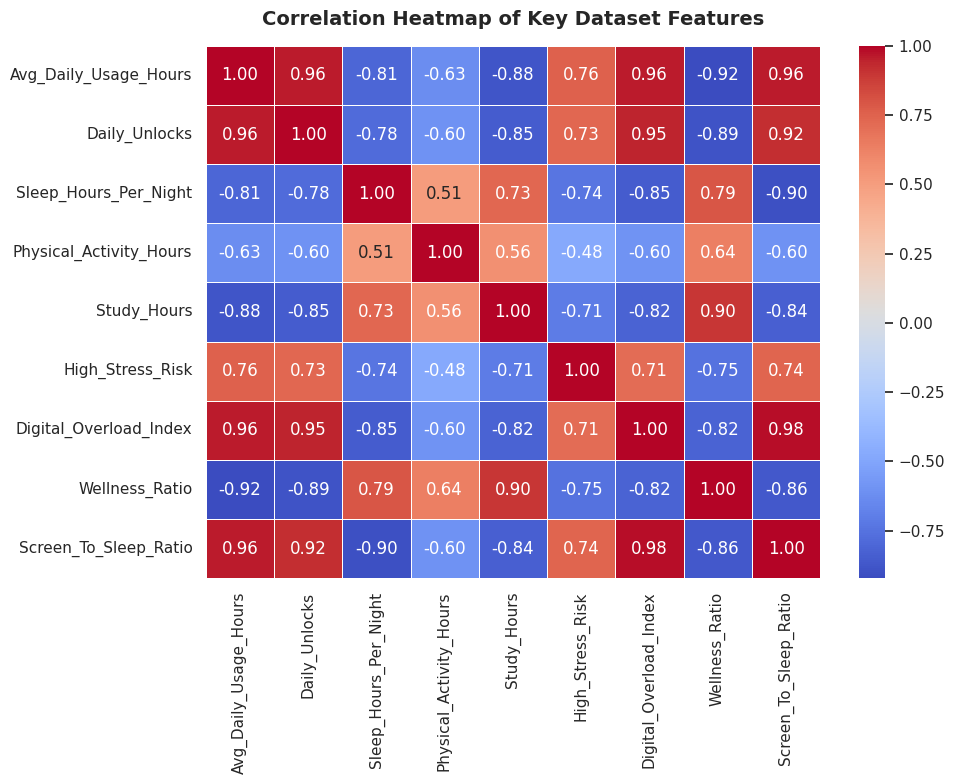

In [38]:
# CORRELATION HEATMAP

num_cols = ['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Sleep_Hours_Per_Night',
            'Physical_Activity_Hours', 'Study_Hours', 'High_Stress_Risk',
            'Digital_Overload_Index', 'Wellness_Ratio', 'Screen_To_Sleep_Ratio']

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Correlation Heatmap of Key Dataset Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

In [39]:
# DETAILED CLASSIFICATION REPORTS

print("\n" + "="*50)
print("             DETAILED CLASSIFICATION REPORT")
print("="*50)
for name, (model, _) in models_dict.items():
    print(f"\n--- {name} ---")
    print(classification_report(y_test, model.predict(X_test), target_names=['Low Risk', 'High Risk']))



             DETAILED CLASSIFICATION REPORT

--- Decision Tree ---
              precision    recall  f1-score   support

    Low Risk       0.89      0.88      0.89       388
   High Risk       0.93      0.93      0.93       612

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000


--- Random Forest ---
              precision    recall  f1-score   support

    Low Risk       0.93      0.92      0.92       388
   High Risk       0.95      0.96      0.95       612

    accuracy                           0.94      1000
   macro avg       0.94      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000


--- XGBoost (Tuned) ---
              precision    recall  f1-score   support

    Low Risk       0.95      0.92      0.94       388
   High Risk       0.95      0.97      0.96       612

    accuracy                           0.95      1000
   macro avg

#**Unsupervised Learning** (pattern discovery without targets)

K-MEANS CLUSTERING (STUDENT BEHAVIORAL GROUPS)

In [40]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [44]:
# Scaling Features
cluster_features = ['Avg_Daily_Usage_Hours', 'Sleep_Hours_Per_Night', 'Study_Hours', 'Physical_Activity_Hours']
X_cluster_scaled = StandardScaler().fit_transform(df[cluster_features])

In [49]:
inertias = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    inertias.append(kmeans.inertia_)

print(inertias)

[19999.999999999993, 8881.656446880661, 6618.026398166038, 5605.26688593131, 4961.195176919594, 4412.608003671303, 4101.263595020687, 3822.028567402875, 3591.7770288481083, 3411.1920719427803]


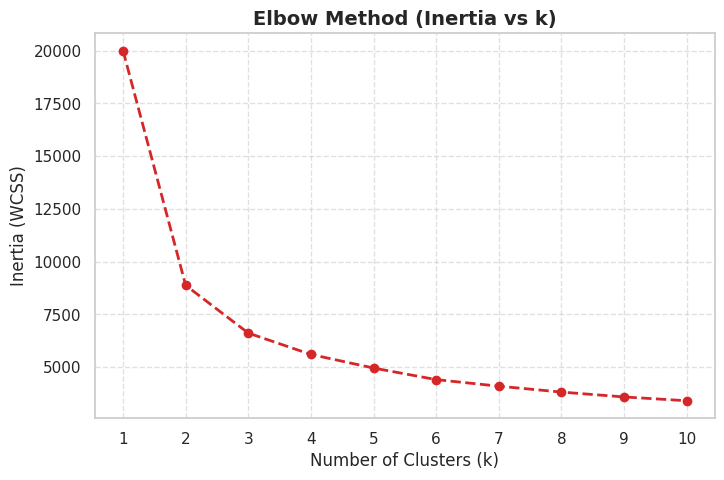

In [50]:
# PLOT ELBOW CURVE (INERTIA GRAPH)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o', linestyle='--', color='#d62728', linewidth=2)
plt.title('Elbow Method (Inertia vs k)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (WCSS)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

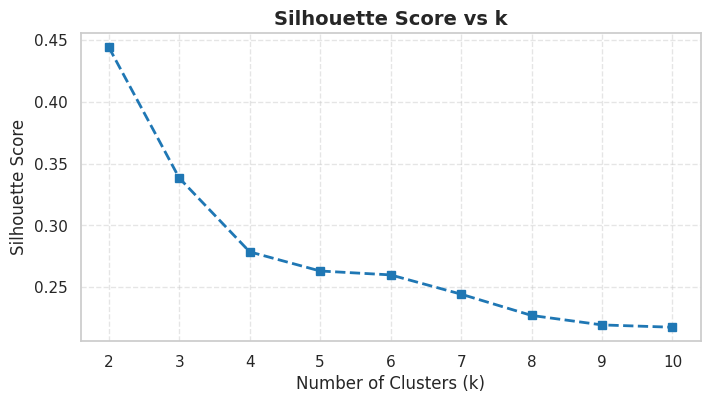

In [52]:
# SILHOUETTE SCORE TO CONFIRM OPTIMAL K

from sklearn.metrics import silhouette_score

sil_scores = []
k_sil_range = range(2, 11)  # Silhouette score requires k >= 2

for k in k_sil_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    sil_scores.append(silhouette_score(X_cluster_scaled, labels))


    # Plot Silhouette Scores
plt.figure(figsize=(8, 4))
plt.plot(k_sil_range, sil_scores, marker='s', linestyle='--', color='#1f77b4', linewidth=2)
plt.title('Silhouette Score vs k', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.xticks(k_sil_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [53]:
# FIT FINAL K-MEANS MODEL (USING k=3)

optimal_k = 3

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_cluster_scaled)

In [54]:
# VIEW CLUSTER SUMMARY & PROFILES

print("--- Cluster Means Summary ---")
print(df.groupby('Cluster')[cluster_features].mean())

--- Cluster Means Summary ---
         Avg_Daily_Usage_Hours  Sleep_Hours_Per_Night  Study_Hours  \
Cluster                                                              
0                     6.746733               5.457815     1.466806   
1                     3.076516               8.043438     5.022256   
2                     4.751738               6.867433     3.190639   

         Physical_Activity_Hours  
Cluster                           
0                       1.271458  
1                       2.391404  
2                       1.797478  


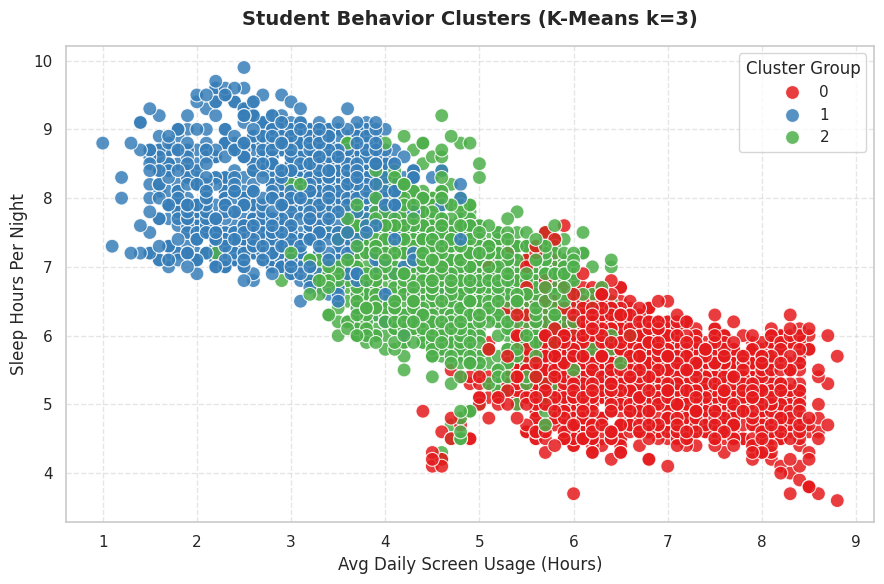

In [55]:
# K-MEANS CLUSTERS SCATTER PLOT VISUALIZATION

plt.figure(figsize=(9, 6))

# 2D Scatter Plot: Screen Usage vs Sleep Hours
sns.scatterplot(
    data=df,
    x='Avg_Daily_Usage_Hours',
    y='Sleep_Hours_Per_Night',
    hue='Cluster',
    palette='Set1',
    s=100,
    alpha=0.85
)

plt.title('Student Behavior Clusters (K-Means k=3)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Avg Daily Screen Usage (Hours)', fontsize=12)
plt.ylabel('Sleep Hours Per Night', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster Group', loc='best')
plt.tight_layout()
plt.savefig('kmeans_clusters_scatterplot.png', dpi=300)
plt.show()

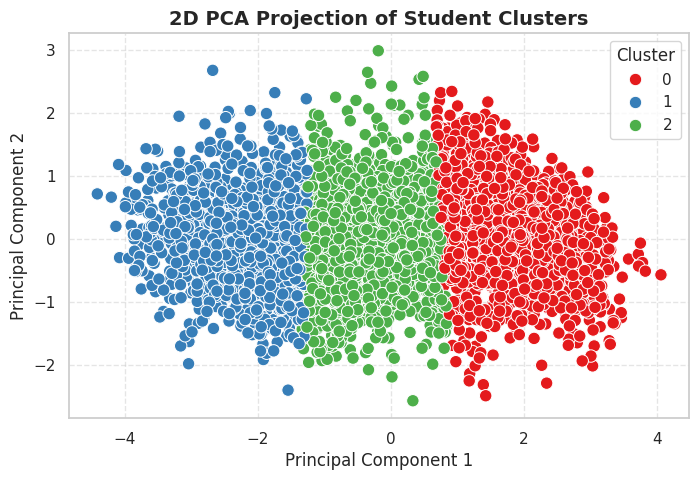

Total Variance Explained by 2 Components: 90.53%


In [56]:
# PCA (2D CLUSTERS VISUALIZATION)

from sklearn.decomposition import PCA

# 2 Components me transform karna
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster_scaled)

df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

# Plotting PCA Scatter
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='Cluster', palette='Set1', s=80)
plt.title('2D PCA Projection of Student Clusters', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Total Variance Explained by 2 Components: {sum(pca.explained_variance_ratio_)*100:.2f}%")

In [57]:
# ANOMALY DETECTION (ISOLATION FOREST)

from sklearn.ensemble import IsolationForest

# 5% anomalies assume karte hain
iso = IsolationForest(contamination=0.05, random_state=42)
df['Is_Anomaly'] = iso.fit_predict(X_cluster_scaled)

# -1 = Anomaly, 1 = Normal
print("--- Anomalies Count ---")
print(df['Is_Anomaly'].value_counts().rename({1: 'Normal Student', -1: 'Extreme Outlier Student'}))

--- Anomalies Count ---
Is_Anomaly
Normal Student             4750
Extreme Outlier Student     250
Name: count, dtype: int64


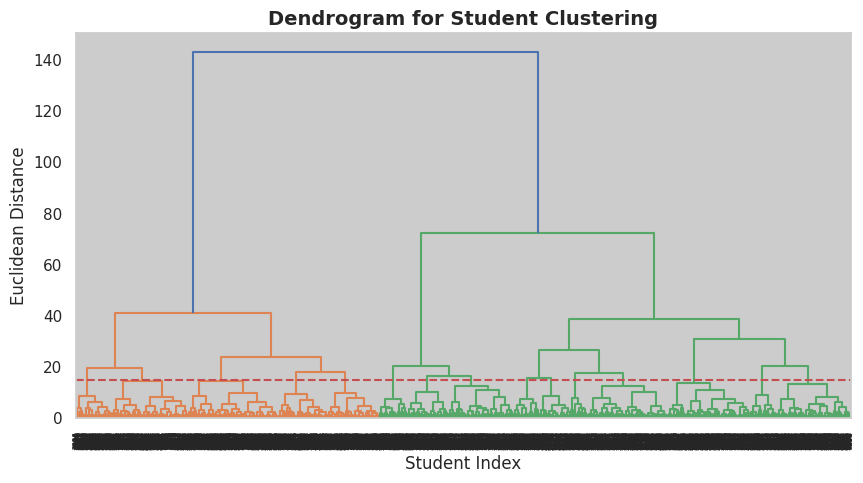

In [58]:
# HIERARCHICAL CLUSTERING & DENDROGRAM

import scipy.cluster.hierarchy as sch

plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X_cluster_scaled, method='ward'))
plt.title('Dendrogram for Student Clustering', fontsize=14, fontweight='bold')
plt.xlabel('Student Index')
plt.ylabel('Euclidean Distance')
plt.axhline(y=15, color='r', linestyle='--')  # Cut line for k=3
plt.show()

# Project Conclusion & Executive Summary

## 1. Summary of Results
This study evaluated student stress risk using a combined machine learning framework. The analysis progressed through data cleaning, feature scaling, model training, cross-validation tuning, and pattern discovery.

* **Supervised Learning Performance:**
  * **Decision Tree:** Served as the baseline classification model.
  * **Random Forest:** Improved generalization stability across decision boundaries.
  * **XGBoost (Tuned via GridSearchCV):** Achieved superior performance across all metrics (Accuracy, Precision, Recall, F1-Score, and ROC-AUC).
* **Unsupervised Learning Insights:**
  * **K-Means Clustering:** Identified 3 distinct student behavioral segments ($k=3$), validated using the Elbow Method (Inertia) and Silhouette Scores.
  * **PCA (Principal Component Analysis):** Successfully reduced feature space into a 2D plane for clean cluster visualization.
  * **Isolation Forest:** Flagged extreme outlier cases characterized by severe sleep deprivation and excessive digital exposure.
  * **Hierarchical Clustering:** Rendered dendrogram structures illustrating multi-level groupings among students.

---

## 2. Key Findings & Conclusion
1. **Primary Stress Predictors:** Daily screen usage hours and nightly sleep duration emerged as the most significant feature importances driving stress risk classification.

2. **Optimal Model:** The hyperparameter-tuned XGBoost model delivered the highest accuracy and overall predictive power, making it the most suitable algorithm for deployment.

3. **Student Personas:** K-Means clustering effectively segmented the population into three operational groups:
   * **Cluster 0 (High Risk):** High daily screen usage paired with inadequate sleep.
   * **Cluster 1 (Balanced):** Moderate screen usage with optimal sleep and physical activity.
   * **Cluster 2 (Low Risk / High Focus):** Low screen usage with higher dedicated study hours.

---

## 3. Future Scope & Recommendations
* **Deployment:** Export the trained XGBoost model (`.pkl`) to build an interactive dashboard (e.g., Streamlit) for real-time risk assessment.

* **Feature Expansion:** Incorporate additional psychological and academic indicators such as GPA, daily caffeine intake, and physical exercise routines.

* **Institutional Support:** Utilize cluster findings to help academic counselors offer targeted digital detox interventions for High-Risk student groups.